<a href="https://colab.research.google.com/github/iRosses/ageing-clock-disagreement/blob/main/clock_trust_pilot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# When can we trust an ageing clock?
Pilot on public data (GSE40279, Hannum et al., 656 people, whole blood, ages 19–101).

**Question:** different epigenetic clocks give different ages for the same person. For whom do they disagree, and can we flag people whose estimate is unreliable?

Run in Google Colab: `Runtime → Run all`. Downloading the dataset takes a few minutes the first time.

## 1. Run several published clocks on the same people

In [1]:
!pip -q install biolearn

In [2]:
!wget -c --tries=10 --user-agent="Mozilla/5.0" "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE40nnn/GSE40279/matrix/GSE40279_series_matrix.txt.gz"
!ls -lh GSE40279*

--2026-11-01 22:40:29--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE40nnn/GSE40279/matrix/GSE40279_series_matrix.txt.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.7, 130.14.250.10, 2607:f220:41e:250::13, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.7|:443... connected.
HTTP request sent, awaiting response... 416 Requested Range Not Satisfiable

    The file is already fully retrieved; nothing to do.

-rw-r--r-- 1 root root 1.2G Aug 21  2012 GSE40279_average_beta.txt.gz
-rw-r--r-- 1 root root 1.2G Oct  3 09:45 GSE40279_series_matrix.txt.gz


In [3]:
import gzip, gc, numpy as np, pandas as pd, matplotlib.pyplot as plt
from biolearn.data_library import GeoData
from biolearn.model_gallery import ModelGallery

path = "GSE40279_series_matrix.txt.gz"

rows, start = {}, None
with gzip.open(path, "rt") as f:
    for i, line in enumerate(f):
        if line.startswith("!Sample_"):
            key, *vals = line.rstrip("\n").split("\t")
            rows.setdefault(key, []).append([v.strip('"') for v in vals])
        if line.startswith("!series_matrix_table_begin"):
            start = i + 1
            break

meta = pd.DataFrame(index=rows["!Sample_geo_accession"][0])
for vals in rows["!Sample_characteristics_ch1"]:
    k = vals[0].split(":")[0].strip().lower()
    meta[k] = [v.split(":", 1)[1].strip() if ":" in v else None for v in vals]
meta = meta.rename(columns={"age (y)": "age", "gender": "sex"})
meta["age"] = pd.to_numeric(meta["age"], errors="coerce")
print("metadata:", meta.shape)

header = pd.read_csv(path, sep="\t", skiprows=start, nrows=0).columns
dtypes = {c: "float32" for c in header[1:]}
parts = []
for n, chunk in enumerate(pd.read_csv(path, sep="\t", skiprows=start, index_col=0,
                                      dtype=dtypes, na_values=["null", ""],
                                      chunksize=50000, comment="!")):
    parts.append(chunk)
    print("chunk", n + 1)
dnam = pd.concat(parts); del parts; gc.collect()
dnam.index = dnam.index.str.strip('"')
dnam.columns = dnam.columns.str.strip('"')
print("methylation:", dnam.shape)

data = GeoData(meta, dnam)
print("ready")

metadata: (656, 6)
chunk 1
chunk 2
chunk 3
chunk 4
chunk 5
chunk 6
chunk 7
chunk 8
chunk 9
chunk 10
methylation: (473034, 656)
ready


In [4]:
gallery = ModelGallery()
clock_names = ["Horvathv1", "Hannum", "PhenoAge", "Horvathv2", "Lin", "Zhang_10"]
preds = {}
for name in clock_names:
    try:
        preds[name] = gallery.get(name).predict(data)["Predicted"]
        print("ok  ", name)
    except Exception as e:
        print("skip", name, "->", e)

P = pd.DataFrame(preds)
df = meta.join(P, how="inner")
clocks = list(P.columns)
age = df["age"].astype(float)
print(len(df), "people,", len(clocks), "clocks")

ok   Horvathv1
ok   Hannum
ok   PhenoAge
ok   Horvathv2
ok   Lin
ok   Zhang_10
656 people, 6 clocks


           Horvathv1  Hannum  PhenoAge  Horvathv2   Lin  Zhang_10
Horvathv1       1.00    0.61      0.53       0.63  0.60      0.30
Hannum          0.61    1.00      0.56       0.62  0.57      0.43
PhenoAge        0.53    0.56      1.00       0.50  0.49      0.46
Horvathv2       0.63    0.62      0.50       1.00  0.50      0.16
Lin             0.60    0.57      0.49       0.50  1.00      0.27
Zhang_10        0.30    0.43      0.46       0.16  0.27      1.00


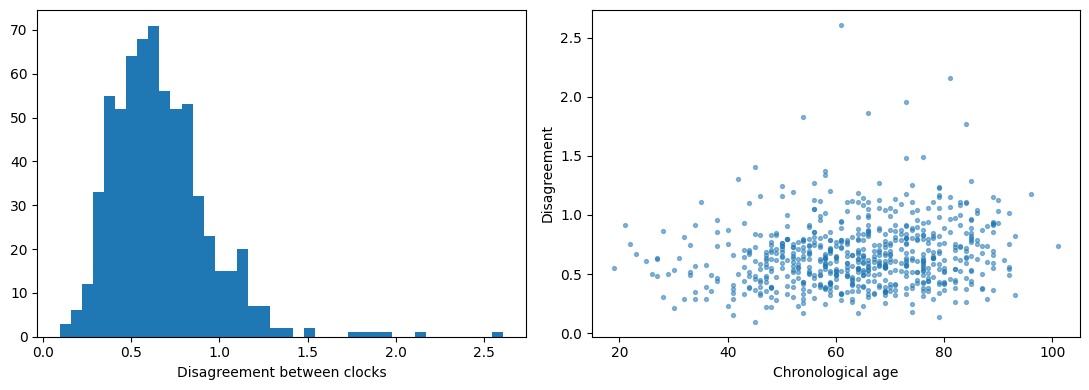

In [5]:
accel = pd.DataFrame(index=df.index)
for c in clocks:
    b, a = np.polyfit(age, df[c], 1)
    r = df[c] - (b * age + a)
    accel[c] = (r - r.mean()) / r.std()

df["disagreement"] = accel.std(axis=1)
print(accel.corr().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df["disagreement"], bins=40); ax[0].set_xlabel("Disagreement between clocks")
ax[1].scatter(age, df["disagreement"], s=8, alpha=.5)
ax[1].set_xlabel("Chronological age"); ax[1].set_ylabel("Disagreement")
plt.tight_layout(); plt.show()

In [6]:
df["age_group"] = pd.cut(age, [0, 40, 60, 80, 120], labels=["<40", "40-60", "60-80", "80+"])
for g in ["sex", "ethnicity", "age_group"]:
    print(df.groupby(g)["disagreement"].agg(["count", "mean", "median"]).round(3), "\n")

     count   mean  median
sex                      
F      338  0.663   0.635
M      318  0.665   0.624 

                      count   mean  median
ethnicity                                 
Caucasian - European    426  0.678   0.636
Hispanic - Mexican      230  0.637   0.624 

           count   mean  median
age_group                      
<40           38  0.588   0.557
40-60        223  0.624   0.615
60-80        305  0.673   0.622
80+           90  0.764   0.735 



/tmp/ipykernel_11241/2872133864.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(g)["disagreement"].agg(["count", "mean", "median"]).round(3), "\n")


Horvathv1: 90% interval = ±9.2 years
coverage all: 86.0% | top-20% disagreement: 72.7% | others: 89.3%
median error: top-20% 6.1 y vs others 3.8 y
Spearman rho: 0.191


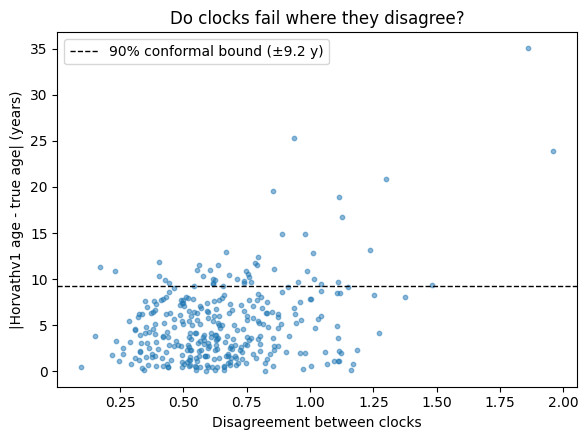

In [7]:
rng = np.random.default_rng(0)
idx = rng.permutation(df.index); half = len(idx) // 2
cal, test = idx[:half], idx[half:]

target = "Horvathv1" if "Horvathv1" in clocks else clocks[0]
b, a = np.polyfit(age[cal], df.loc[cal, target], 1)
err = ((df[target] - a) / b - age).abs()

q = np.quantile(err[cal], min(1.0, np.ceil((half + 1) * 0.9) / half))
hi = df.loc[test, "disagreement"] > df.loc[test, "disagreement"].quantile(.8)
print(f"{target}: 90% interval = ±{q:.1f} years")
print(f"coverage all: {(err[test] <= q).mean():.1%} | top-20% disagreement: {(err[test][hi] <= q).mean():.1%} | others: {(err[test][~hi] <= q).mean():.1%}")
print(f"median error: top-20% {err[test][hi].median():.1f} y vs others {err[test][~hi].median():.1f} y")
print("Spearman rho:", round(df.loc[test, "disagreement"].corr(err[test], method="spearman"), 3))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(df.loc[test, "disagreement"], err[test], s=10, alpha=.5)
ax.axhline(q, ls="--", c="k", lw=1, label=f"90% conformal bound (±{q:.1f} y)")
ax.set_xlabel("Disagreement between clocks"); ax.set_ylabel(f"|{target} age - true age| (years)")
ax.set_title("Do clocks fail where they disagree?"); ax.legend()
plt.tight_layout(); plt.savefig("main_figure.png", dpi=200); plt.show()

In [8]:
results = []
for seed in range(20):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(df.index); half = len(idx) // 2
    cal, test = idx[:half], idx[half:]
    b, a = np.polyfit(age[cal], df.loc[cal, target], 1)
    err = ((df[target] - a) / b - age).abs()
    d = df["disagreement"]

    # normal interval (same width for everyone)
    q = np.quantile(err[cal], min(1.0, np.ceil((half + 1) * 0.9) / half))
    # adaptive interval: width grows with disagreement
    s = err[cal] / d[cal]
    qs = np.quantile(s, min(1.0, np.ceil((half + 1) * 0.9) / half))

    hi = d[test] > d[test].quantile(.8)
    results.append({
        "normal_all": (err[test] <= q).mean(),
        "normal_highDis": (err[test][hi] <= q).mean(),
        "adaptive_all": (err[test] <= qs * d[test]).mean(),
        "adaptive_highDis": (err[test][hi] <= qs * d[test][hi]).mean(),
    })

print(pd.DataFrame(results).mean().round(3))

normal_all          0.896
normal_highDis      0.771
adaptive_all        0.896
adaptive_highDis    0.933
dtype: float64


In [9]:
rows = []
for seed in range(20):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(df.index); half = len(idx) // 2
    cal, test = idx[:half], idx[half:]
    b, a = np.polyfit(age[cal], df.loc[cal, target], 1)
    err = ((df[target] - a) / b - age).abs()
    d = df["disagreement"]
    lvl = min(1.0, np.ceil((half + 1) * 0.9) / half)
    q = np.quantile(err[cal], lvl)
    qs = np.quantile(err[cal] / d[cal], lvl)
    lo = d[test] <= d[test].quantile(.8)
    rows.append({
        "normal_lowDis_cov": (err[test][lo] <= q).mean(),
        "adaptive_lowDis_cov": (err[test][lo] <= qs * d[test][lo]).mean(),
        "normal_width_lowDis": 2 * q,
        "adaptive_width_lowDis": (2 * qs * d[test][lo]).median(),
        "adaptive_width_highDis": (2 * qs * d[test][~lo]).median(),
    })
print(pd.DataFrame(rows).mean().round(2))

normal_lowDis_cov          0.93
adaptive_lowDis_cov        0.89
normal_width_lowDis       19.43
adaptive_width_lowDis     18.36
adaptive_width_highDis    32.76
dtype: float64


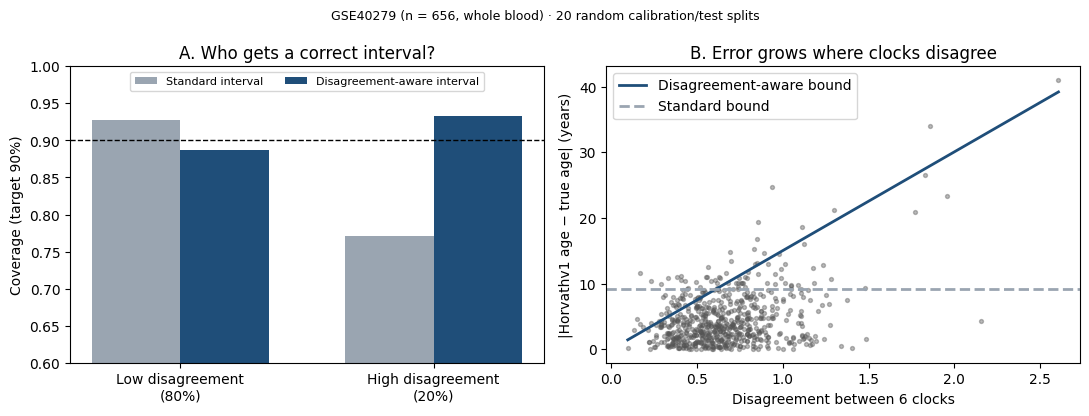

In [11]:
cov = pd.DataFrame(results).mean()
low = pd.DataFrame(rows).mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

labels = ["Low disagreement\n(80%)", "High disagreement\n(20%)"]
x = np.arange(2); w = 0.35
ax[0].bar(x - w/2, [low["normal_lowDis_cov"], cov["normal_highDis"]], w, label="Standard interval", color="#9aa5b1")
ax[0].bar(x + w/2, [low["adaptive_lowDis_cov"], cov["adaptive_highDis"]], w, label="Disagreement-aware interval", color="#1f4e79")
ax[0].axhline(0.9, ls="--", c="k", lw=1)
ax[0].set_xticks(x); ax[0].set_xticklabels(labels); ax[0].set_ylim(0.6, 1.0)
ax[0].set_ylabel("Coverage (target 90%)"); ax[0].set_title("A. Who gets a correct interval?"); ax[0].legend(loc="upper center", fontsize=8, ncol=2)

d = df["disagreement"]
ax[1].scatter(d, err, s=8, alpha=.4, color="#555")
xs = np.linspace(d.min(), d.max(), 100)
ax[1].plot(xs, qs * xs, c="#1f4e79", lw=2, label="Disagreement-aware bound")
ax[1].axhline(q, ls="--", c="#9aa5b1", lw=2, label="Standard bound")
ax[1].set_xlabel("Disagreement between 6 clocks"); ax[1].set_ylabel(f"|{target} age − true age| (years)")
ax[1].set_title("B. Error grows where clocks disagree"); ax[1].legend()

fig.suptitle("GSE40279 (n = 656, whole blood) · 20 random calibration/test splits", fontsize=9)
plt.tight_layout(); plt.savefig("main_figure.png", dpi=200); plt.show()